In [6]:
import numpy as np
import matplotlib.pyplot as plt

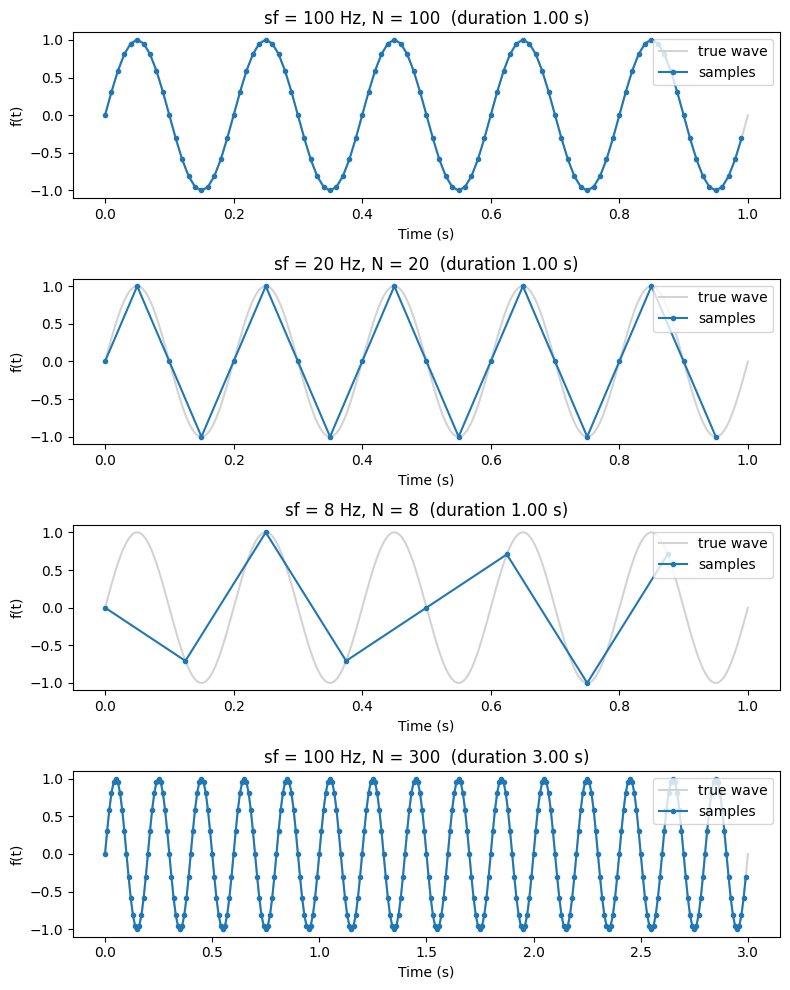

In [7]:
"""-----TASK 1-----"""

def sine_wave(a, hz, sf, N):
    """
    Discrete samples of f(t) = a*sin(2*pi*hz*t).

    a  : amplitude
    hz : wave frequency in Hz
    sf : sample frequency in Hz (samples per second)
    N  : number of samples
    Returns (t, f): the sample times and the sampled values.
    """
    # Sample n is taken at time t_n = n / sf, for n = 0, 1, ..., N-1.
    # np.arange(N) gives [0, 1, ..., N-1]; dividing by sf converts to seconds.
    t = np.arange(N) / sf

    # Evaluate the wave at every sample time at once (NumPy works element-wise).
    f = a * np.sin(2 * np.pi * hz * t)
    return t, f


# --- Parameters for the wave itself ---
a = 1.0      # amplitude
hz = 5.0     # 5 Hz sine wave

# --- Different (sample frequency, number of samples) cases to compare ---
cases = [(100, 100),   # sf well above the wave frequency
         (20, 20),     # fewer samples per cycle
         (8, 8),       # sf below 2*hz: watch what happens
         (100, 300)]   # more samples: longer time window

# A "continuous" reference: sampled very finely so it looks smooth.
# It must last as long as the longest case (sf = 100, N = 300 lasts 3 s),
# otherwise the grey line stops early on that plot.
longest = max(N / sf for sf, N in cases)
t_ref, f_ref = sine_wave(a, hz, sf=10000, N=int(10000 * longest))

# One subplot per case, stacked vertically.
fig, axes = plt.subplots(len(cases), 1, figsize=(8, 10))

for ax, (sf, N) in zip(axes, cases):
    t, f = sine_wave(a, hz, sf, N)
    duration = N / sf   # total time covered by the samples

    # Grey line = the true wave, over the same time window
    mask = t_ref < duration
    ax.plot(t_ref[mask], f_ref[mask], color="lightgrey", label="true wave")

    # Dots joined by lines = what the computer actually stores
    ax.plot(t, f, "o-", markersize=3, label="samples")

    ax.set_title(f"sf = {sf} Hz, N = {N}  (duration {duration:.2f} s)")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("f(t)")
    ax.legend(loc="upper right")

plt.tight_layout()   # stops titles and labels overlapping
plt.show()

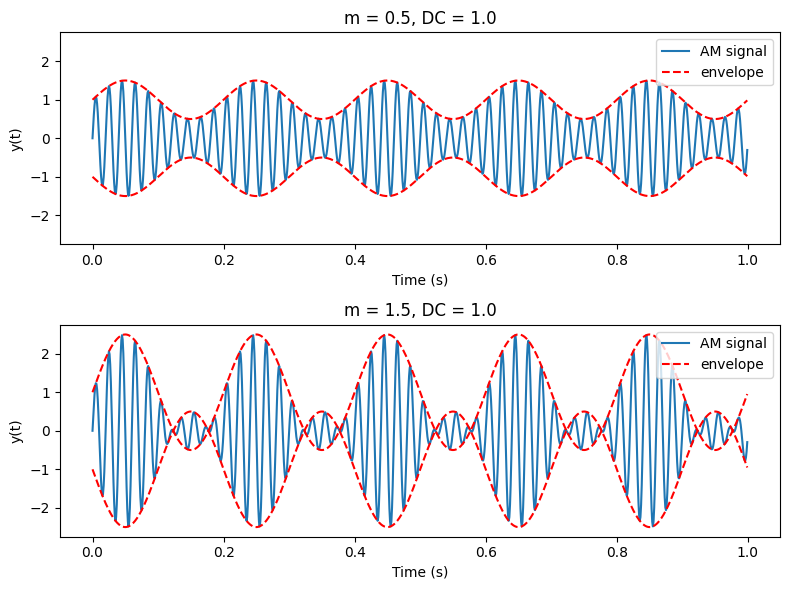

In [8]:
"""-----TASK 2-----"""
def am_signal(A, DC, m, nu_m, nu_c, fs, N):
    """
    Discrete samples of the AM signal
        y(t) = [DC + m*sin(2*pi*nu_m*t)] * A*sin(2*pi*nu_c*t)

    A    : signal amplitude
    DC   : DC offset added to the message
    m    : modulation amplitude
    nu_m : modulation (message) frequency in Hz
    nu_c : carrier frequency in Hz
    fs   : sample frequency in Hz
    N    : number of samples
    """
    t = np.arange(N) / fs                              # same sample times as Task 1
    message = DC + m * np.sin(2 * np.pi * nu_m * t)    # slowly varying envelope term
    carrier = A * np.sin(2 * np.pi * nu_c * t)         # fast carrier
    y = message * carrier                              # AM: the message multiplies the carrier
    return t, y


# --- Baseline parameters (reused in Tasks 3 and 4) ---
A, DC, m = 1.0, 1.0, 0.5
nu_m, nu_c = 5.0, 50.0       # 5 Hz message on a 50 Hz carrier
fs, N = 1000, 1000           # 1 s of data sampled at 1 kHz

# Compare two modulation amplitudes: m < DC and m > DC
fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharey=True)   # same y-axis so the two cases compare directly
for ax, m_demo in zip(axes, [0.5, 1.5]):
    t, y = am_signal(A, DC, m_demo, nu_m, nu_c, fs, N)
    envelope = A * (DC + m_demo * np.sin(2 * np.pi * nu_m * t))   # the bracket term, scaled by A

    ax.plot(t, y, label="AM signal")
    ax.plot(t, envelope, "r--", label="envelope")
    ax.plot(t, -envelope, "r--")                       # mirror image below the axis
    ax.set_title(f"m = {m_demo}, DC = {DC}")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("y(t)")
    ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

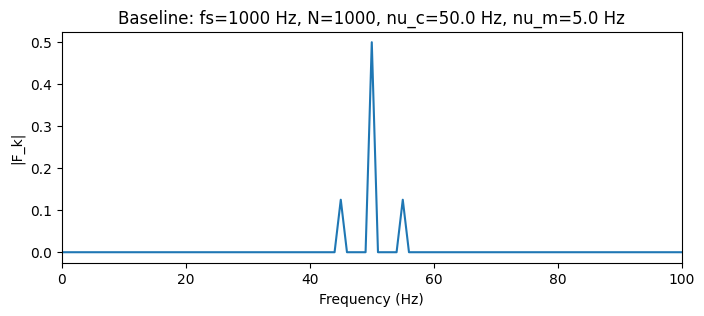

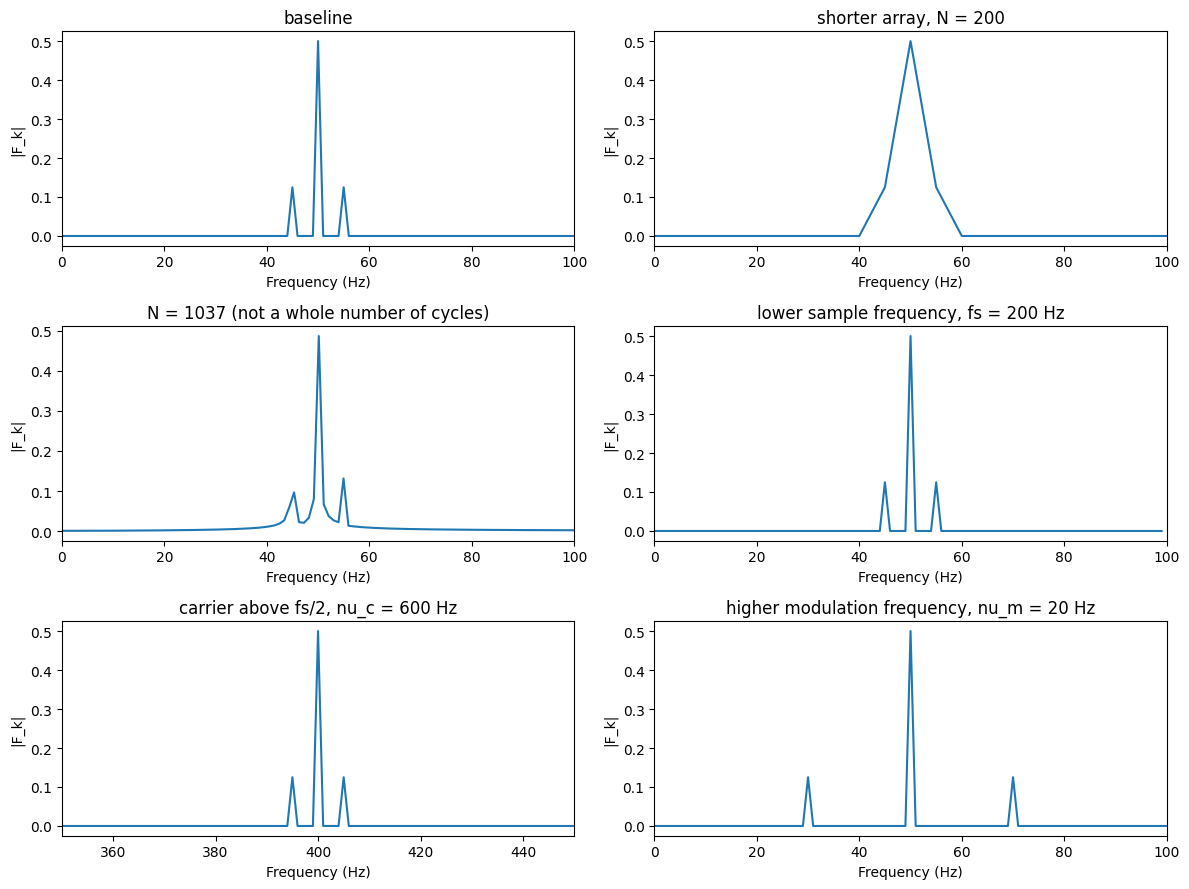

Same result? True
Largest difference: 4.2816584692812026e-14
my_dft: 18.36 ms    np.fft.fft: 1.969 ms


In [9]:
"""-----TASK 3-----"""
import time

def my_dft(f):
    """
    DFT exactly as written on the lab sheet:
        F_k = (1/N) * sum_{n=0}^{N-1} f_n * exp(-i*2*pi*k*n/N)
    """
    N = len(f)
    n = np.arange(N)                          # all sample indices at once
    F = np.zeros(N, dtype=complex)            # output is complex
    for k in range(N):                        # one frequency bin per loop
        F[k] = np.sum(f * np.exp(-1j * 2 * np.pi * k * n / N)) / N
    return F


def freq_axis(N, fs):
    """Bin index k -> Hz:  x(k) = k / (fs^-1 * N) = k * fs / N."""
    return np.arange(N) * fs / N


def plot_spectrum(ax, y, fs, title):
    """Compute my_dft of y and plot |F_k| against real frequency."""
    N = len(y)
    F = my_dft(y)
    freqs = freq_axis(N, fs)
    half = N // 2                             # first half of the array = the real frequencies
    ax.plot(freqs[:half], np.abs(F[:half]))
    ax.set_title(title)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("|F_k|")


# --- 1. Baseline spectrum using my own DFT ---
t, y = am_signal(A, DC, m, nu_m, nu_c, fs, N)
fig, ax = plt.subplots(figsize=(8, 3))
plot_spectrum(ax, y, fs, f"Baseline: fs={fs} Hz, N={N}, nu_c={nu_c} Hz, nu_m={nu_m} Hz")
ax.set_xlim(0, 100)                           # zoom in around the carrier
plt.show()

# --- 2. Explore: change one thing at a time ---
cases = [
    # (fs,   N,    nu_c, nu_m, description)
    (1000, 1000,  50,   5,   "baseline"),
    (1000, 200,   50,   5,   "shorter array, N = 200"),
    (1000, 1037,  50,   5,   "N = 1037 (not a whole number of cycles)"),
    (200,  200,   50,   5,   "lower sample frequency, fs = 200 Hz"),
    (1000, 1000,  600,  5,   "carrier above fs/2, nu_c = 600 Hz"),
    (1000, 1000,  50,   20,  "higher modulation frequency, nu_m = 20 Hz"),
]
windows = [(0, 100)] * 4 + [(350, 450), (0, 100)]    # zoom each plot to where its peaks are
fig, axes = plt.subplots(3, 2, figsize=(12, 9))       # 3 x 2 grid so each plot is a readable size
for ax, (fs_i, N_i, nuc_i, num_i, desc), xlim in zip(axes.flat, cases, windows):
    _, y_i = am_signal(A, DC, m, num_i, nuc_i, fs_i, N_i)
    plot_spectrum(ax, y_i, fs_i, desc)
    ax.set_xlim(*xlim)
plt.tight_layout()
plt.show()

# --- 3. Compare my DFT with NumPy's FFT ---
start = time.perf_counter()
F_mine = my_dft(y)
t_mine = time.perf_counter() - start

start = time.perf_counter()
F_fft = np.fft.fft(y) / N       # NumPy's FFT has no 1/N factor, so divide to match the lab's formula
t_fft = time.perf_counter() - start

print("Same result?", np.allclose(F_mine, F_fft))
print("Largest difference:", np.max(np.abs(F_mine - F_fft)))
print(f"my_dft: {t_mine*1e3:.2f} ms    np.fft.fft: {t_fft*1e3:.3f} ms")

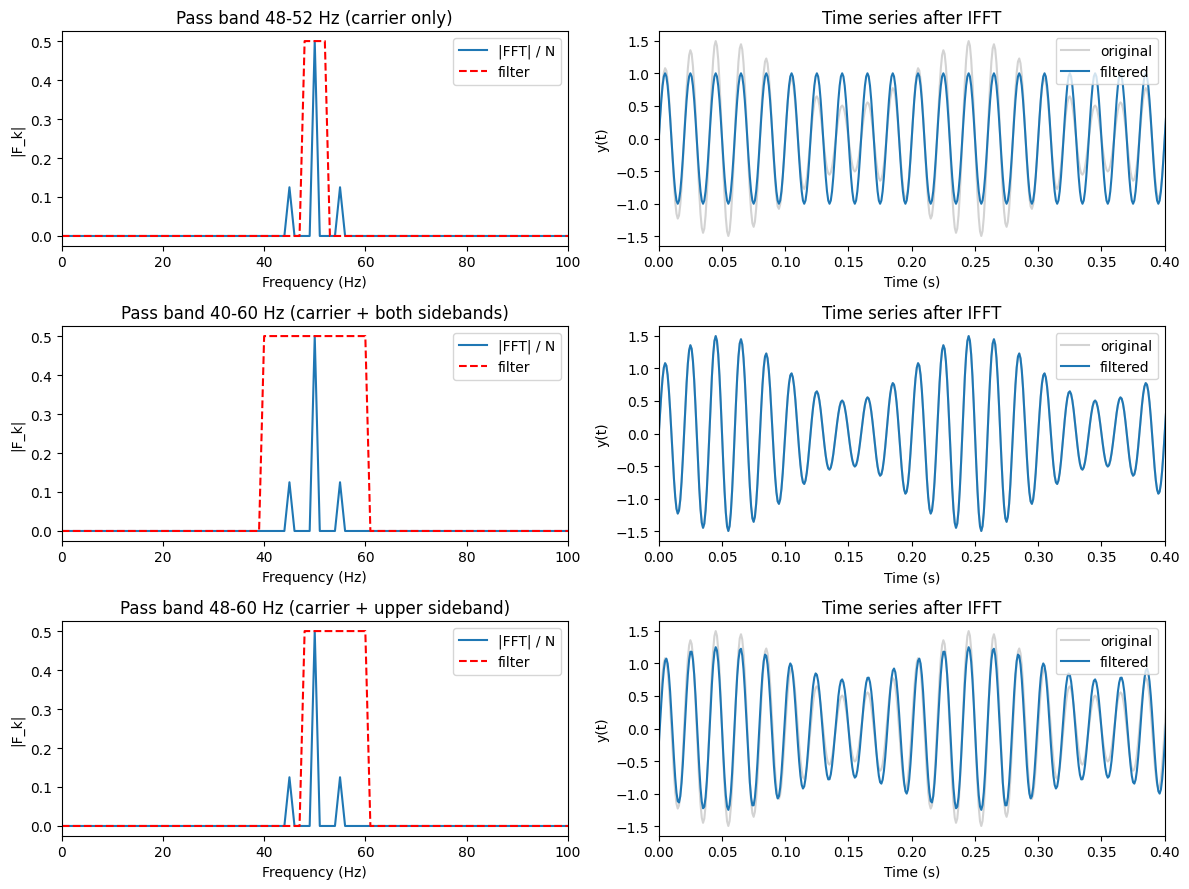

In [10]:
"""-----TASK 4-----"""
def bandpass(y, fs, f_low, f_high):
    """
    Square bandpass filter applied by multiplying in k-space.
    Keeps components with f_low <= |frequency| <= f_high and zeros the rest.
    """
    N = len(y)
    Y = np.fft.fft(y)                           # to the frequency domain
    freqs = np.fft.fftfreq(N, d=1/fs)           # signed frequency (Hz) of each bin
    # Pass BOTH +f and -f, otherwise the result of the IFFT isn't a real signal
    H = ((np.abs(freqs) >= f_low) & (np.abs(freqs) <= f_high)).astype(float)
    y_filt = np.fft.ifft(Y * H).real            # multiply by the filter, then back to time
    # .real just drops tiny imaginary rounding errors (~1e-16)
    return y_filt, freqs, Y, H


t, y = am_signal(A, DC, m, nu_m, nu_c, fs, N)   # baseline signal from Task 2

filters = [(48, 52, "carrier only"),
           (40, 60, "carrier + both sidebands"),
           (48, 60, "carrier + upper sideband")]

fig, axes = plt.subplots(len(filters), 2, figsize=(12, 9))
for row, (f_low, f_high, desc) in zip(axes, filters):
    y_filt, freqs, Y, H = bandpass(y, fs, f_low, f_high)
    pos = freqs >= 0                            # plot positive frequencies only

    # Left: spectrum with the filter window drawn over it
    row[0].plot(freqs[pos], np.abs(Y[pos]) / N, label="|FFT| / N")
    row[0].plot(freqs[pos], H[pos] * np.abs(Y).max() / N, "r--", label="filter")
    row[0].set_xlim(0, 100)
    row[0].set_title(f"Pass band {f_low}-{f_high} Hz ({desc})")
    row[0].set_xlabel("Frequency (Hz)")
    row[0].set_ylabel("|F_k|")
    row[0].legend()

    # Right: original vs filtered time series
    row[1].plot(t, y, color="lightgrey", label="original")
    row[1].plot(t, y_filt, label="filtered")
    row[1].set_xlim(0, 0.4)                     # zoom to two message cycles
    row[1].set_title("Time series after IFFT")
    row[1].set_xlabel("Time (s)")
    row[1].set_ylabel("y(t)")
    row[1].legend(loc="upper right")

plt.tight_layout()
plt.show()